# BÀI 6 : TRANSFER LEARNING VỚI EFFICIENTNET-B0 TRÊN FGVC-AIRCRAFT

**Chủ đề:** Phân loại **FGVC-Aircraft** (100 dòng máy bay - mức `variant`) bằng mô hình **EfficientNet-B0 pretrained ImageNet-1K**.
**Môi trường bắt buộc:** **Google Colab GPU (CUDA)**. Chọn **Runtime → Change runtime type → T4 GPU**, sau đó **Runtime → Run all**.
> **Lưu ý đối chứng:** Scratch/Partial/Full chạy 5 epoch, Linear Probe chạy 25 epoch trên embeddings 1.280 chiều được cache.

### Kết quả học tập & Mục tiêu thực hành
1. Áp dụng quy trình **Transfer Learning** (Scratch, Linear Probing, Partial Fine-tuning, Full Fine-tuning) sang kiến trúc hiện đại **EfficientNet-B0**.
2. Tải và tiền xử lý bộ dữ liệu phân loại chi tiết (**Fine-Grained Visual Classification**) **FGVC-Aircraft** (100 lớp) đúng chuẩn ImageNet.
3. Thay thế classifier head của EfficientNet-B0 (`model.classifier[1]`, đặc trưng **1.280 chiều**) và kiểm tra số tham số học được.
4. Quản lý đóng băng các khối `features`, khóa thống kê BatchNorm (`Frozen BN`), áp dụng learning rate theo tầng và cache embedding.
5. Đánh giá qua **validation loss / top-1 / macro-F1 / top-5**; chọn mô hình tốt nhất chỉ bằng validation và kiểm thử trên tập test đúng một lần.
6. Phân tích ma trận nhầm lẫn, trực quan hóa các mẫu máy bay dự đoán sai và lưu/tải lại checkpoint.

**Nguồn dữ liệu:** https://www.robots.ox.ac.uk/~vgg/data/fgvc-aircraft/  
**PyTorch EfficientNet-B0:** https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.efficientnet_b0.html


## Nội dung thực hành

| Phần | Nội dung trọng tâm | Kết quả cần nộp |
|---|---|---|
| 1 | Dataset FGVC-Aircraft (100 lớp), pretrained EfficientNet-B0, thay head `1280 -> 100` | Kiểm tra tensor / số tham số / chia dữ liệu |
| 2 | Huấn luyện từ đầu (**Scratch**) và **Linear Probing** với backbone đóng băng | Bảng loss, accuracy, macro-F1, learning curves |
| 3 | **Partial** và **Full fine-tuning**, Frozen BatchNorm, learning rate theo tầng | So sánh 4 cách học trên validation |
| 4 | Đánh giá Test độc lập, phân tích nhầm lẫn, ảnh sai, lưu/tải checkpoint | Bảng tổng kết và nhận xét kết quả |

**Quy tắc khoa học:** không xem tập test khi chỉnh mô hình; chọn checkpoint và chiến lược tốt nhất hoàn toàn dựa trên `val_loss`.

## 0. Thiết lập và kiểm soát tái lập

- **Sử dụng CUDA:** Notebook cố định `DEVICE = torch.device("cuda:0")`.
- **Seed = 42:** Đảm bảo khả năng tái lập kết quả.
- **Thời lượng:** Số epoch cấu hình là `5/25/5/5` cho Scratch/Probe/Partial/Full (giống khung đối chứng của bài mẫu).
- **Pretrained Weights:** Sử dụng `EfficientNet_B0_Weights.DEFAULT` của `torchvision.models`.


In [6]:
import copy
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, models, transforms
from torchvision.models import EfficientNet_B0_Weights

SEED = 42
BATCH_SIZE = 32
NUM_WORKERS = 2
IMAGE_SIZE = 224
ANNOTATION_LEVEL = "variant"  # Mức phân loại chi tiết gồm 100 biến thể máy bay
NUM_CLASSES = 100
EPOCHS_SCRATCH = 5
EPOCHS_PROBE = 25
EPOCHS_PARTIAL = 5
EPOCHS_FULL = 5
PATIENCE = 4
DATA_DIR = Path("./data")
OUTPUT_DIR = Path("./bai6_aircraft_efficientnet_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert torch.cuda.is_available(), "Bài tập yêu cầu GPU CUDA: Trên Colab chọn Runtime → Change runtime type → T4 GPU."
DEVICE = torch.device("cuda:0")
WEIGHTS = EfficientNet_B0_Weights.DEFAULT


def set_seed(seed: int = SEED) -> None:
    """Đặt seed cho các thư viện để đảm bảo tính tái lập."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()
print("Torch:", torch.__version__, "| Torchvision:", __import__("torchvision").__version__)
print("Thiết bị:", DEVICE, "| Seed:", SEED)
print("Thư mục lưu mô hình:", OUTPUT_DIR.resolve())


Torch: 2.6.0+cu124 | Torchvision: 0.21.0+cu124
Thiết bị: cuda:0 | Seed: 42
Thư mục lưu mô hình: C:\Users\ad\Desktop\THAI\tuan6-hien\bai6_aircraft_efficientnet_outputs


## 1. Dữ liệu FGVC-Aircraft và bài toán phân loại chi tiết (Fine-Grained)

**FGVC-Aircraft** gồm 10.000 ảnh máy bay thực tế chia đều thành **3.334 train**, **3.333 validation** và **3.333 test**. Ở mức nhãn chuẩn `annotation_level="variant"`, bộ dữ liệu có **100 lớp** (tương đương ~33 ảnh/lớp trong mỗi tập train/val).

**Đặc thù bài toán:** Khác với nhận diện vật thể thông thường, các dòng máy bay (như Boeing 737-300 và Boeing 737-400) có cấu trúc tổng thể rất giống nhau, chỉ khác ở chi tiết nhỏ như động cơ, cánh đuôi, cửa sổ hoặc tỷ lệ thân.

| Khái niệm | Trong bài thực hành |
|---|---|
| **Source domain** | Ảnh màu tự nhiên thuộc ImageNet-1K |
| **Source task** | Phân loại 1.000 lớp ImageNet |
| **Target domain** | Ảnh máy bay FGVC-Aircraft |
| **Target task** | Phân loại 100 biến thể máy bay (`variant`) |
| **Backbone** | EfficientNet-B0 giữ chức năng trích xuất đặc trưng (`model.features`) |
| **Head** | Lớp `Linear(1280, 100)` thay thế `model.classifier[1]` |


## 2. Chuẩn hóa theo pretrained weights, Dataset và DataLoader

EfficientNet-B0 pretrained ImageNet sử dụng ảnh RGB chuẩn hóa `mean=[0.485, 0.456, 0.406]`, `std=[0.229, 0.224, 0.225]` và kích thước `224×224`.
- **Train:** `RandomResizedCrop`, lật ngang (`RandomHorizontalFlip`), `ColorJitter` nhẹ, `ToTensor`, `Normalize`.
- **Validation/Test & Cached features:** biến đổi xác định (`WEIGHTS.transforms()`: `Resize(256) → CenterCrop(224) → ToTensor → Normalize`).
- **Lưu ý tự động tải dữ liệu:** Hàm `datasets.FGVCAircraft(..., download=True)` sẽ tự động truy cập trang dữ liệu gốc của Đại học Oxford, tải gói `fgvc-aircraft-2013b.tar.gz`, giải nén và nạp thẳng vào PyTorch.


In [7]:
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.72, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.12, contrast=0.12, saturation=0.12),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_transform = WEIGHTS.transforms()  # Resize 256 + CenterCrop 224 + Normalize

# Tự động tải và giải nén bộ dữ liệu FGVC-Aircraft từ máy chủ Oxford
aircraft_train = datasets.FGVCAircraft(
    DATA_DIR, split="train", annotation_level=ANNOTATION_LEVEL,
    download=True, transform=train_transform
)
aircraft_train_clean = datasets.FGVCAircraft(
    DATA_DIR, split="train", annotation_level=ANNOTATION_LEVEL,
    download=False, transform=eval_transform
)
aircraft_val = datasets.FGVCAircraft(
    DATA_DIR, split="val", annotation_level=ANNOTATION_LEVEL,
    download=False, transform=eval_transform
)

CLASS_NAMES = aircraft_train.classes
assert len(CLASS_NAMES) == NUM_CLASSES
assert len(aircraft_train) == len(aircraft_train_clean) == 3334
assert len(aircraft_val) == 3333

train_loader = DataLoader(aircraft_train, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
train_clean_loader = DataLoader(aircraft_train_clean, batch_size=BATCH_SIZE, shuffle=False,
                                num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(aircraft_val, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=True)

print("Train:", len(aircraft_train), "| Validation:", len(aircraft_val), "| Số lớp:", NUM_CLASSES)
print("Ví dụ 5 tên lớp đầu tiên:", CLASS_NAMES[:5])
sample_images, sample_labels = next(iter(train_loader))
print("Một batch:", tuple(sample_images.shape), "| Nhãn:", tuple(sample_labels.shape))
assert sample_images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)


Train: 3334 | Validation: 3333 | Số lớp: 100
Ví dụ 5 tên lớp đầu tiên: ['707-320', '727-200', '737-200', '737-300', '737-400']
Một batch: (32, 3, 224, 224) | Nhãn: (32,)


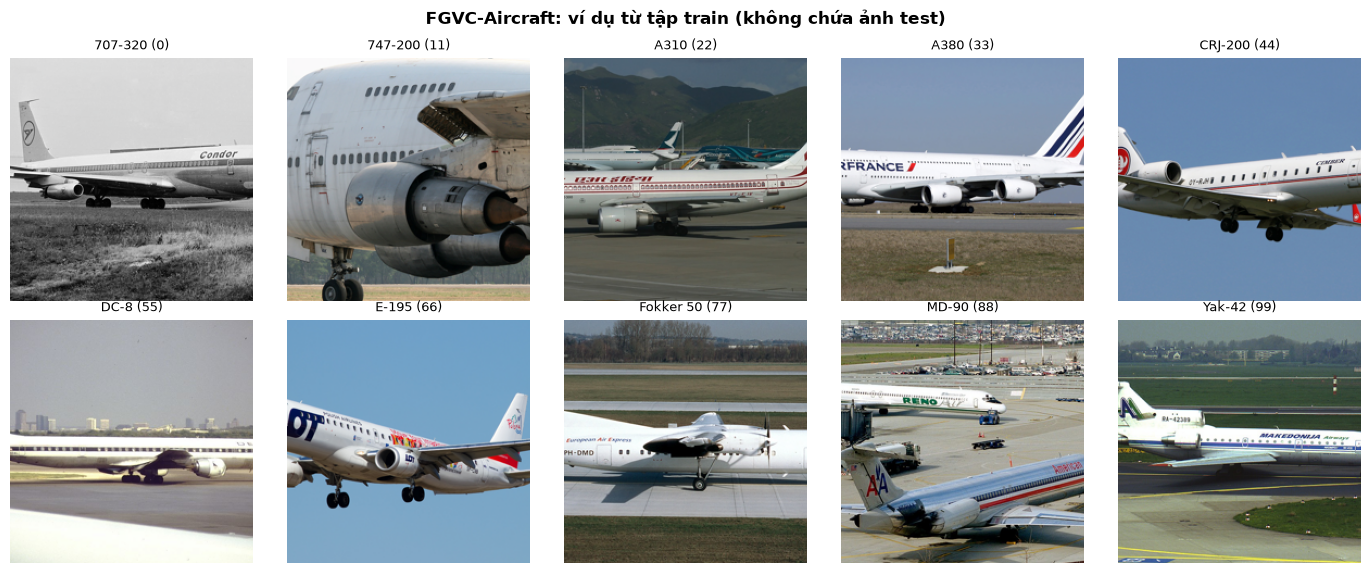

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(14, 5.8))
for ax, idx in zip(axes.flat, np.linspace(0, len(aircraft_train_clean) - 1, 10, dtype=int)):
    img, target = aircraft_train_clean[int(idx)]
    arr = img.permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)
    ax.imshow(np.clip(arr, 0.0, 1.0))
    ax.set_title(f"{CLASS_NAMES[target]} ({target})", fontsize=9)
    ax.axis("off")
fig.suptitle("FGVC-Aircraft: ví dụ từ tập train (không chứa ảnh test)", weight="bold")
plt.tight_layout()
plt.show()


## 3. Khám phá pretrained EfficientNet-B0: backbone, head và số tham số

**EfficientNet-B0** sử dụng các khối inverted residual (MBConv) kết hợp cơ chế Squeeze-and-Excitation (SE), tối ưu hóa đồng thời độ sâu, độ rộng và độ phân giải. Biểu diễn đặc trưng trước classifier có **1.280 chiều** (so với 512 chiều của ResNet18).

- **Cấu trúc phân tầng của EfficientNet-B0 trong `torchvision`:**
  - `model.features`: Gồm 9 khối tuần tự đánh số từ `0` đến `8` (từ stem conv đầu vào đến conv 1×1 mở rộng lên 1.280 kênh).
  - `model.avgpool`: Global Average Pooling đưa về vector `(N, 1280, 1, 1)`.
  - `model.classifier`: `Sequential(Dropout(p=0.2), Linear(1280, 1000))` $\rightarrow$ Ta thay `model.classifier[1] = nn.Linear(1280, 100)`.
- **Chiến lược đóng băng & Learning rate:**
  - `probe`: Đóng băng toàn bộ `features`, chỉ mở `classifier`.
  - `partial`: Mở các khối trích xuất đặc trưng cấp cao cuối cùng (`features[6:]`) cùng `classifier`, giữ nguyên running stats của các lớp BatchNorm.
  - `full`: Mở toàn bộ mạng với 4 nhóm learning rate tăng dần từ tầng thấp (`features[:5]`: `1e-5`) lên tầng cao (`features[5:7]`: `3e-5`, `features[7:]`: `1e-4`) và lớp phân loại mới (`classifier`: `1e-3`).


In [9]:
def count_parameters(model: nn.Module) -> dict[str, int]:
    """Đếm tổng số tham số và số tham số được phép học."""
    total = sum(param.numel() for param in model.parameters())
    trainable = sum(param.numel() for param in model.parameters() if param.requires_grad)
    return {"Total": total, "Trainable": trainable, "Frozen": total - trainable}


def build_efficientnet_b0(num_classes: int = NUM_CLASSES, pretrained: bool = True) -> nn.Module:
    """Khởi tạo EfficientNet-B0 và thay classifier head theo số lớp đích (1280 -> num_classes)."""
    model = models.efficientnet_b0(weights=WEIGHTS if pretrained else None)
    in_features = model.classifier[1].in_features  # 1280
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model


def configure_trainable(model: nn.Module, strategy: str) -> nn.Module:
    """Chọn lớp trainable: scratch, probe, partial, full cho EfficientNet-B0."""
    if strategy not in ("scratch", "probe", "partial", "full"):
        raise ValueError(f"Chiến lược không được hỗ trợ: {strategy}")
    for parameter in model.parameters():
        parameter.requires_grad = strategy in ("scratch", "full")
    if strategy in ("probe", "partial"):
        for parameter in model.classifier.parameters():
            parameter.requires_grad = True
    if strategy == "partial":
        # Mở các khối đặc trưng cấp cao cuối cùng (tương đương layer4 của ResNet18)
        for parameter in model.features[6:].parameters():
            parameter.requires_grad = True
    return model


def set_training_mode(model: nn.Module, strategy: str) -> None:
    """Phân biệt `train()` với `requires_grad`; giữ Frozen BN ở eval."""
    model.train()
    if strategy in ("probe", "partial"):
        for module in model.modules():
            if isinstance(module, nn.modules.batchnorm._BatchNorm):
                module.eval()


def build_optimizer(model: nn.Module, strategy: str) -> torch.optim.Optimizer:
    """Head học nhanh hơn backbone; tham số đóng băng không đưa vào optimizer."""
    if strategy == "scratch":
        return torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),
                                 lr=1e-3, weight_decay=1e-4)
    if strategy == "probe":
        return torch.optim.AdamW(model.classifier.parameters(), lr=3e-3, weight_decay=1e-3)
    if strategy == "partial":
        return torch.optim.AdamW([
            {"params": model.features[6:].parameters(), "lr": 1e-4},
            {"params": model.classifier.parameters(), "lr": 1e-3},
        ], weight_decay=1e-4)
    if strategy == "full":
        return torch.optim.AdamW([
            {"params": model.features[:5].parameters(), "lr": 1e-5},
            {"params": model.features[5:7].parameters(), "lr": 3e-5},
            {"params": model.features[7:].parameters(), "lr": 1e-4},
            {"params": model.classifier.parameters(), "lr": 1e-3},
        ], weight_decay=1e-4)
    raise ValueError(strategy)


shape_demo = build_efficientnet_b0(num_classes=NUM_CLASSES, pretrained=False)
probe_demo = configure_trainable(copy.deepcopy(shape_demo), "probe")
partial_demo = configure_trainable(copy.deepcopy(shape_demo), "partial")
full_demo = configure_trainable(copy.deepcopy(shape_demo), "full")
display(pd.DataFrame([
    {"Chiến lược": "Scratch", **count_parameters(shape_demo)},
    {"Chiến lược": "Frozen + head", **count_parameters(probe_demo)},
    {"Chiến lược": "Features[6:] + head", **count_parameters(partial_demo)},
    {"Chiến lược": "All layers", **count_parameters(full_demo)},
]))
assert probe_demo.classifier[1].out_features == NUM_CLASSES
assert 0 < count_parameters(probe_demo)["Trainable"] < count_parameters(partial_demo)["Trainable"]
assert count_parameters(partial_demo)["Trainable"] < count_parameters(full_demo)["Trainable"]
del shape_demo, probe_demo, partial_demo, full_demo


,Chiến lược,Total,Trainable,Frozen
0,Scratch,4135648,4135648,0
1,Frozen + head,4135648,128100,4007548
2,Features[6:] + head,4135648,3283840,851808
3,All layers,4135648,4135648,0


## 4. Bộ hàm train / evaluate / trực quan hóa tái sử dụng

Giữ nguyên pipeline chuẩn hóa từ bài mẫu:
- Tính tổng loss theo từng mẫu (`reduction="sum"` / chia cho tổng mẫu).
- Chỉ lưu checkpoint tốt nhất dựa theo **validation loss** (`val_loss`).
- Báo cáo đồng thời `val_loss`, `val_acc` (Top-1), `val_macroF1` và `val_top5`.


In [10]:
def evaluate(model: nn.Module, loader: DataLoader, num_classes: int = NUM_CLASSES) -> dict:
    """Đánh giá đầy đủ theo mẫu, trả về nhãn để tính macro-F1 và top-k."""
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction="sum")
    total_loss, total, correct_1, correct_5 = 0.0, 0, 0, 0
    all_targets, all_preds = [], []
    with torch.inference_mode():
        for inputs, targets in loader:
            inputs = inputs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            logits = model(inputs)
            total_loss += criterion(logits, targets).item()
            preds = logits.argmax(dim=1)
            correct_1 += int((preds == targets).sum())
            correct_5 += int((logits.topk(min(5, num_classes), dim=1).indices ==
                               targets.unsqueeze(1)).any(dim=1).sum())
            total += targets.size(0)
            all_targets.extend(targets.cpu().tolist())
            all_preds.extend(preds.cpu().tolist())
    assert total > 0
    return {"loss": total_loss / total, "accuracy": correct_1 / total,
            "top5": correct_5 / total,
            "macro_f1": f1_score(all_targets, all_preds, labels=list(range(num_classes)),
                                 average="macro", zero_division=0),
            "targets": np.asarray(all_targets), "preds": np.asarray(all_preds)}


def fit_model(name: str, model: nn.Module, train_data: DataLoader,
              val_data: DataLoader, strategy: str, epochs: int,
              num_classes: int = NUM_CLASSES) -> tuple[nn.Module, pd.DataFrame, dict]:
    """Huấn luyện, in từng epoch, lưu best checkpoint theo validation loss."""
    model = model.to(DEVICE)
    optimizer = build_optimizer(model, strategy)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(1, epochs))
    criterion = nn.CrossEntropyLoss()
    history, best_state = [], None
    best_loss, best_epoch, patience_count = float("inf"), 0, 0
    start = time.perf_counter()
    for epoch in range(1, epochs + 1):
        set_training_mode(model, strategy)
        total_loss, num_seen = 0.0, 0
        for inputs, targets in train_data:
            inputs = inputs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(inputs)
            loss = criterion(logits, targets)
            loss.backward()
            optimizer.step()
            total_loss += float(loss.item()) * len(targets)
            num_seen += len(targets)
        val_metrics = evaluate(model, val_data, num_classes)
        epoch_record = {"epoch": epoch, "train_loss": total_loss / num_seen,
                        "val_loss": val_metrics["loss"], "val_acc": val_metrics["accuracy"],
                        "val_f1": val_metrics["macro_f1"], "val_top5": val_metrics["top5"]}
        history.append(epoch_record)
        print(f"[{name}] {epoch:02d}/{epochs:02d} | train_loss={epoch_record['train_loss']:.4f} "
              f"| val_loss={epoch_record['val_loss']:.4f} | val_acc={epoch_record['val_acc']:.2%} "
              f"| val_macroF1={epoch_record['val_f1']:.4f}")
        if val_metrics["loss"] < best_loss - 1e-6:
            best_loss, best_epoch, patience_count = val_metrics["loss"], epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            patience_count += 1
        scheduler.step()
        if patience_count >= PATIENCE:
            print(f"[{name}] Early stopping tại epoch {epoch}.")
            break
    if best_state is None:
        raise RuntimeError("Không có checkpoint hợp lệ")
    model.load_state_dict(best_state)
    metrics = evaluate(model, val_data, num_classes)
    seconds = time.perf_counter() - start
    summary = {"Mô hình": name, "Best epoch": best_epoch,
               "Val loss": metrics["loss"], "Val accuracy": metrics["accuracy"],
               "Val macro-F1": metrics["macro_f1"], "Val top-5": metrics["top5"],
               "Thời gian (s)": round(seconds, 1),
               "Trainable": count_parameters(model)["Trainable"]}
    print(f"[{name}] BEST epoch={best_epoch}, val_loss={metrics['loss']:.4f}, "
          f"val_accuracy={metrics['accuracy']:.2%}")
    return model, pd.DataFrame(history), summary


def plot_histories(histories: dict[str, pd.DataFrame], title: str) -> None:
    """Trực quan hóa lịch sử trên train/validation của các phương pháp."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    for name, frame in histories.items():
        axes[0].plot(frame.epoch, frame.val_acc, marker="o", label=name)
        axes[1].plot(frame.epoch, frame.train_loss, linestyle="--", alpha=0.5,
                     label=f"{name} train")
        axes[1].plot(frame.epoch, frame.val_loss, marker="o", label=f"{name} val")
    axes[0].set(xlabel="Epoch", ylabel="Accuracy", title="Validation accuracy", ylim=(0, 1))
    axes[1].set(xlabel="Epoch", ylabel="Cross-entropy", title="Train loss / Val loss")
    for ax in axes:
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


## 5. Thí nghiệm A — EfficientNet-B0 **huấn luyện từ đầu** (Scratch baseline)

Khởi tạo ngẫu nhiên (`pretrained=False`) và tối ưu toàn bộ 4,13 triệu tham số trong 5 epoch để làm mốc đối chứng.


In [11]:
histories, fitted_models, summaries = {}, {}, {}
set_seed(SEED)
scratch_model = configure_trainable(build_efficientnet_b0(pretrained=False), "scratch")
scratch_model, histories["Scratch"], summaries["Scratch"] = fit_model(
    "Scratch", scratch_model, train_loader, val_loader,
    strategy="scratch", epochs=EPOCHS_SCRATCH)
fitted_models["Scratch"] = scratch_model.cpu()
display(pd.DataFrame([summaries["Scratch"]]).round(4))
del scratch_model
torch.cuda.empty_cache()


[Scratch] 01/05 | train_loss=4.6687 | val_loss=5.5815 | val_acc=2.34% | val_macroF1=0.0084
[Scratch] 02/05 | train_loss=4.4739 | val_loss=4.3907 | val_acc=2.97% | val_macroF1=0.0071
[Scratch] 03/05 | train_loss=4.2629 | val_loss=4.4089 | val_acc=2.97% | val_macroF1=0.0095
[Scratch] 04/05 | train_loss=4.0054 | val_loss=3.9557 | val_acc=6.12% | val_macroF1=0.0314
[Scratch] 05/05 | train_loss=3.7633 | val_loss=3.8190 | val_acc=8.04% | val_macroF1=0.0521
[Scratch] BEST epoch=5, val_loss=3.8190, val_accuracy=8.04%


,Mô hình,Best epoch,Val loss,Val accuracy,Val macro-F1,Val top-5,Thời gian (s),Trainable
0,Scratch,5,3.819,0.0804,0.0521,0.2826,620.9,4135648


## 6. Thí nghiệm B — **Frozen feature extractor + Linear Probing** (1.280 chiều)

Đóng băng toàn bộ backbone `EfficientNet-B0` pretrained ImageNet-1K, trích xuất vector đặc trưng **1.280 chiều** cho 3.334 ảnh train và 3.333 ảnh validation, sau đó huấn luyện lớp tuyến tính `Linear(1280, 100)` trong 25 epoch.


In [12]:
def extract_features(pretrained_model: nn.Module, loader: DataLoader) -> TensorDataset:
    """Trích xuất vector đặc trưng 1.280 chiều cho mỗi ảnh; không tính gradient."""
    backbone = copy.deepcopy(pretrained_model)
    backbone.classifier = nn.Identity()
    backbone = backbone.to(DEVICE).eval()
    vectors, labels = [], []
    with torch.inference_mode():
        for images, targets in loader:
            features = backbone(images.to(DEVICE, non_blocking=True))
            vectors.append(features.cpu())
            labels.append(targets.clone())
    del backbone
    return TensorDataset(torch.cat(vectors), torch.cat(labels))


class LinearProbe(nn.Module):
    """Head tuyến tính dùng cho embeddings 1.280 chiều của EfficientNet-B0."""
    def __init__(self, in_features: int = 1280, out_features: int = NUM_CLASSES):
        super().__init__()
        self.classifier = nn.Linear(in_features, out_features)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(x)


pretrained_probe = build_efficientnet_b0(pretrained=True)
cached_train = extract_features(pretrained_probe, train_clean_loader)
cached_val = extract_features(pretrained_probe, val_loader)
print("Cached train:", tuple(cached_train.tensors[0].shape),
      "| Cached val:", tuple(cached_val.tensors[0].shape))

probe_train_loader = DataLoader(cached_train, batch_size=128, shuffle=True)
probe_val_loader = DataLoader(cached_val, batch_size=256, shuffle=False)
set_seed(SEED)
probe_head = LinearProbe(in_features=1280, out_features=NUM_CLASSES)
probe_head, histories["Linear probe"], summaries["Linear probe"] = fit_model(
    "Linear probe", probe_head, probe_train_loader, probe_val_loader,
    strategy="probe", epochs=EPOCHS_PROBE)

# Ghép head đã học vào lại mô hình EfficientNet-B0 để đánh giá trên ảnh gốc
pretrained_probe.classifier[1].load_state_dict(probe_head.classifier.cpu().state_dict())
fitted_models["Linear probe"] = configure_trainable(pretrained_probe.cpu(), "probe")
summaries["Linear probe"]["Trainable"] = count_parameters(fitted_models["Linear probe"])["Trainable"]
display(pd.DataFrame([summaries["Linear probe"]]).round(4))
del probe_head, cached_train, cached_val, pretrained_probe
torch.cuda.empty_cache()


Cached train: (3334, 1280) | Cached val: (3333, 1280)
[Linear probe] 01/25 | train_loss=4.1016 | val_loss=3.5925 | val_acc=18.12% | val_macroF1=0.1517
[Linear probe] 02/25 | train_loss=3.0851 | val_loss=3.1934 | val_acc=27.33% | val_macroF1=0.2384
[Linear probe] 03/25 | train_loss=2.5982 | val_loss=2.9481 | val_acc=32.64% | val_macroF1=0.3018
[Linear probe] 04/25 | train_loss=2.2581 | val_loss=2.8058 | val_acc=33.96% | val_macroF1=0.3159
[Linear probe] 05/25 | train_loss=2.0243 | val_loss=2.6914 | val_acc=34.47% | val_macroF1=0.3290
[Linear probe] 06/25 | train_loss=1.8278 | val_loss=2.5903 | val_acc=38.70% | val_macroF1=0.3695
[Linear probe] 07/25 | train_loss=1.6685 | val_loss=2.5443 | val_acc=38.25% | val_macroF1=0.3662
[Linear probe] 08/25 | train_loss=1.5455 | val_loss=2.4859 | val_acc=39.90% | val_macroF1=0.3808
[Linear probe] 09/25 | train_loss=1.4276 | val_loss=2.4397 | val_acc=40.26% | val_macroF1=0.3896
[Linear probe] 10/25 | train_loss=1.3281 | val_loss=2.3978 | val_acc=41.1

,Mô hình,Best epoch,Val loss,Val accuracy,Val macro-F1,Val top-5,Thời gian (s),Trainable
0,Linear probe,25,2.2539,0.4461,0.4392,0.7351,1.7,128100


## 7. Thí nghiệm C — **Partial fine-tuning** (`features[6:]` + `classifier`)

Mở khóa các khối trích xuất đặc trưng cấp cao cuối cùng (`features[6:]`) và lớp `classifier`, giữ nguyên thống kê running mean/var của BatchNorm (`Frozen BN`).


In [13]:
set_seed(SEED)
partial_model = configure_trainable(build_efficientnet_b0(pretrained=True), "partial")
print("Số tham số partial:", count_parameters(partial_model))
partial_model, histories["Partial FT"], summaries["Partial FT"] = fit_model(
    "Partial FT", partial_model, train_loader, val_loader,
    strategy="partial", epochs=EPOCHS_PARTIAL)
fitted_models["Partial FT"] = partial_model.cpu()
display(pd.DataFrame([summaries["Partial FT"]]).round(4))
del partial_model
torch.cuda.empty_cache()


Số tham số partial: {'Total': 4135648, 'Trainable': 3283840, 'Frozen': 851808}
[Partial FT] 01/05 | train_loss=3.7501 | val_loss=2.8788 | val_acc=26.55% | val_macroF1=0.2269
[Partial FT] 02/05 | train_loss=2.0044 | val_loss=2.4328 | val_acc=35.94% | val_macroF1=0.3365
[Partial FT] 03/05 | train_loss=1.2037 | val_loss=2.0648 | val_acc=42.93% | val_macroF1=0.4147
[Partial FT] 04/05 | train_loss=0.8204 | val_loss=1.9472 | val_acc=46.95% | val_macroF1=0.4635
[Partial FT] 05/05 | train_loss=0.6028 | val_loss=1.9224 | val_acc=48.36% | val_macroF1=0.4822
[Partial FT] BEST epoch=5, val_loss=1.9224, val_accuracy=48.36%


,Mô hình,Best epoch,Val loss,Val accuracy,Val macro-F1,Val top-5,Thời gian (s),Trainable
0,Partial FT,5,1.9224,0.4836,0.4822,0.7849,277.6,3283840


## 8. Thí nghiệm D — **Full fine-tuning** với learning rate theo tầng

Mở khóa toàn bộ mạng `EfficientNet-B0` pretrained với 4 mức learning rate (`1e-5`, `3e-5`, `1e-4`, `1e-3`) để tinh chỉnh các đặc trưng chi tiết (cánh, động cơ, mũi máy bay) mà không làm phá vỡ đặc trưng cơ bản.


In [14]:
set_seed(SEED)
full_model = configure_trainable(build_efficientnet_b0(pretrained=True), "full")
print("Learning rates (full):", [group["lr"] for group in build_optimizer(full_model, "full").param_groups])
full_model, histories["Full FT"], summaries["Full FT"] = fit_model(
    "Full FT", full_model, train_loader, val_loader,
    strategy="full", epochs=EPOCHS_FULL)
fitted_models["Full FT"] = full_model.cpu()
display(pd.DataFrame([summaries["Full FT"]]).round(4))
del full_model
torch.cuda.empty_cache()


Learning rates (full): [1e-05, 3e-05, 0.0001, 0.001]
[Full FT] 01/05 | train_loss=4.2735 | val_loss=3.5934 | val_acc=20.13% | val_macroF1=0.1672
[Full FT] 02/05 | train_loss=2.8968 | val_loss=2.8106 | val_acc=30.90% | val_macroF1=0.2874
[Full FT] 03/05 | train_loss=2.0743 | val_loss=2.4752 | val_acc=35.64% | val_macroF1=0.3416
[Full FT] 04/05 | train_loss=1.6895 | val_loss=2.3406 | val_acc=39.57% | val_macroF1=0.3819
[Full FT] 05/05 | train_loss=1.5412 | val_loss=2.3010 | val_acc=40.02% | val_macroF1=0.3867
[Full FT] BEST epoch=5, val_loss=2.3010, val_accuracy=40.02%


,Mô hình,Best epoch,Val loss,Val accuracy,Val macro-F1,Val top-5,Thời gian (s),Trainable
0,Full FT,5,2.301,0.4002,0.3867,0.7036,279.8,4135648


## 9. Tổng hợp và so sánh kết quả **validation**

Xếp hạng các mô hình theo `Val loss` tăng dần (nếu bằng nhau xếp theo `Val macro-F1` giảm dần) và chọn duy nhất mô hình đứng đầu để đánh giá trên tập Test.


,Mô hình,Best epoch,Val loss,Val accuracy,Val macro-F1,Val top-5,Thời gian (s),Trainable
0,Partial FT,5,1.9224,0.4836,0.4822,0.7849,277.6,3283840
1,Linear probe,25,2.2539,0.4461,0.4392,0.7351,1.7,128100
2,Full FT,5,2.3010,0.4002,0.3867,0.7036,279.8,4135648
3,Scratch,5,3.8190,0.0804,0.0521,0.2826,620.9,4135648


Mô hình được chọn CHỈ từ validation: Partial FT


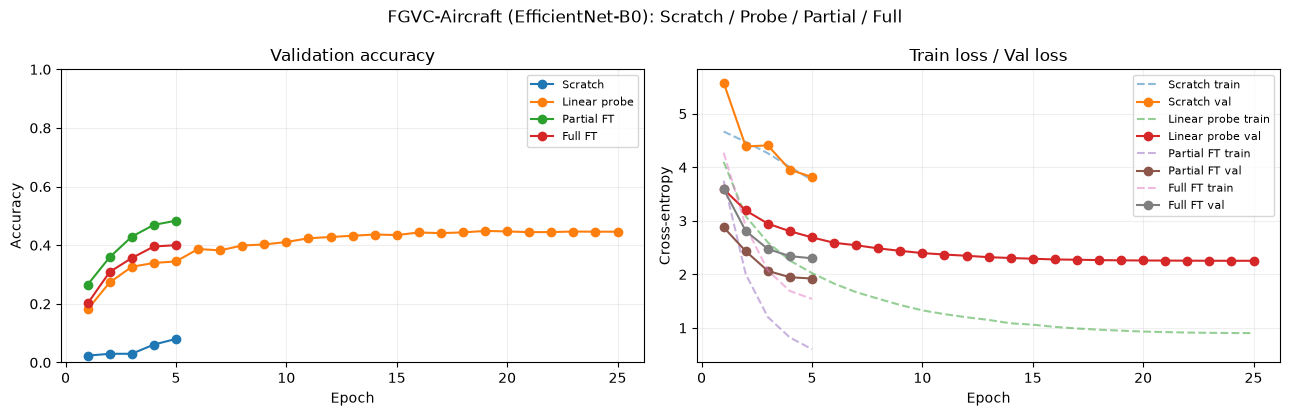

In [15]:
comparison = pd.DataFrame(summaries.values()).sort_values(
    ["Val loss", "Val macro-F1"], ascending=[True, False]).reset_index(drop=True)
display(comparison.round(4))
selected_name = str(comparison.iloc[0]["Mô hình"])
best_model = fitted_models[selected_name].to(DEVICE).eval()
print("Mô hình được chọn CHỈ từ validation:", selected_name)
plot_histories(histories, "FGVC-Aircraft (EfficientNet-B0): Scratch / Probe / Partial / Full")
comparison.to_csv(OUTPUT_DIR / "aircraft_validation_comparison.csv", index=False)


## 10. **Đánh giá test đúng một lần** và phân tích sai số

Nạp tập test chính thức của FGVC-Aircraft (3.333 ảnh) và đánh giá mô hình tốt nhất đã chọn ở Mục 9.


In [16]:
aircraft_test = datasets.FGVCAircraft(
    DATA_DIR, split="test", annotation_level=ANNOTATION_LEVEL,
    download=False, transform=eval_transform
)
assert len(aircraft_test) == 3333
test_loader = DataLoader(aircraft_test, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)

test_metrics = evaluate(best_model, test_loader, NUM_CLASSES)
test_report = pd.DataFrame([{
    "Selected model": selected_name,
    "Test loss": test_metrics["loss"],
    "Test top-1 accuracy": test_metrics["accuracy"],
    "Test macro-F1": test_metrics["macro_f1"],
    "Test top-5 accuracy": test_metrics["top5"],
    "N test": len(aircraft_test),
}])
display(test_report.round(4))
test_report.to_csv(OUTPUT_DIR / "aircraft_final_test_metrics.csv", index=False)


,Selected model,Test loss,Test top-1 accuracy,Test macro-F1,Test top-5 accuracy,N test
0,Partial FT,1.9512,0.4785,0.4771,0.7912,3333


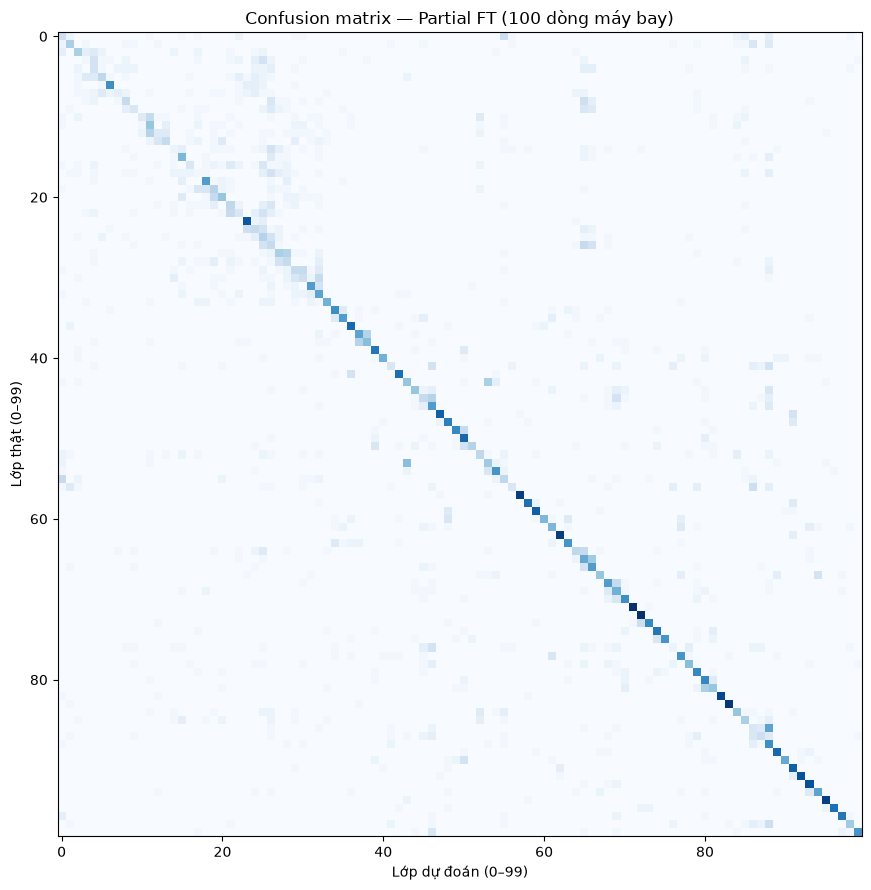

10 dòng máy bay có F1 thấp nhất:


,precision,recall,f1-score,support
767-300,0.040,0.029,0.034,34.0
737-300,0.077,0.030,0.043,33.0
757-200,0.118,0.059,0.078,34.0
Fokker 100,0.154,0.061,0.087,33.0
MD-80,0.128,0.147,0.137,34.0
A321,0.098,0.235,0.138,34.0
737-700,0.429,0.091,0.150,33.0
747-300,0.250,0.121,0.163,33.0
A310,0.185,0.152,0.167,33.0
A320,0.122,0.303,0.174,33.0


In [17]:
cm = confusion_matrix(test_metrics["targets"], test_metrics["preds"],
                      labels=np.arange(NUM_CLASSES))
fig, ax = plt.subplots(figsize=(10, 9))
ax.imshow(cm, interpolation="nearest", cmap="Blues")
ax.set(xlabel="Lớp dự đoán (0–99)", ylabel="Lớp thật (0–99)",
       title=f"Confusion matrix — {selected_name} (100 dòng máy bay)")
plt.tight_layout()
plt.show()

class_report = classification_report(
    test_metrics["targets"], test_metrics["preds"],
    labels=np.arange(NUM_CLASSES), target_names=CLASS_NAMES,
    zero_division=0, output_dict=True)
class_table = pd.DataFrame(class_report).T.iloc[:NUM_CLASSES]
print("10 dòng máy bay có F1 thấp nhất:")
display(class_table.sort_values("f1-score").head(10).round(3))
class_table.to_csv(OUTPUT_DIR / "aircraft_test_per_class_metrics.csv")


Tổng ảnh dự đoán sai: 1738 / 3333


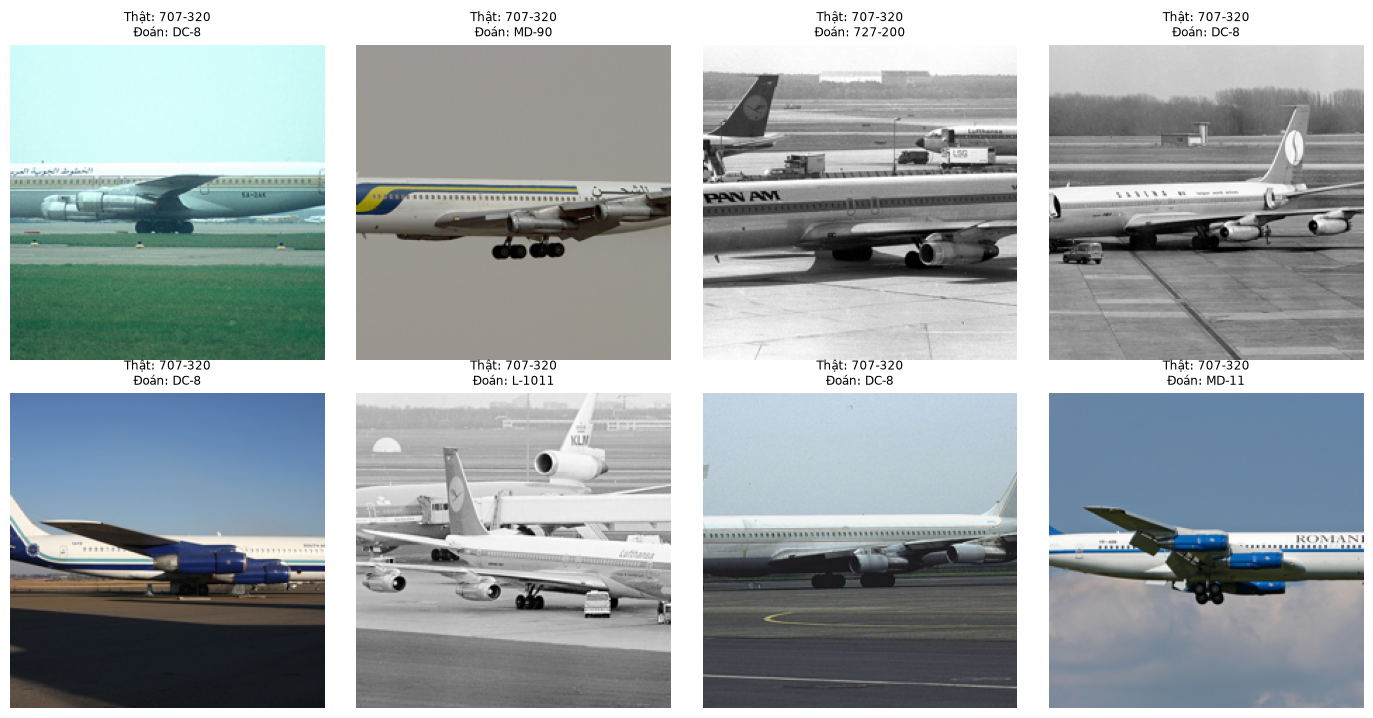

In [18]:
mistakes = np.where(test_metrics["targets"] != test_metrics["preds"])[0]
print("Tổng ảnh dự đoán sai:", len(mistakes), "/", len(aircraft_test))
if len(mistakes) > 0:
    fig, axes = plt.subplots(2, 4, figsize=(14, 7.2))
    for ax, idx in zip(axes.flat, mistakes[:8]):
        tensor, true_label = aircraft_test[int(idx)]
        arr = tensor.permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)
        ax.imshow(np.clip(arr, 0.0, 1.0))
        pred_label = test_metrics["preds"][idx]
        ax.set_title(f"Thật: {CLASS_NAMES[true_label]}\nĐoán: {CLASS_NAMES[pred_label]}", fontsize=8.5)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


## 11. Lưu / tải checkpoint và suy luận thử một ảnh

Lưu trọng số mô hình tốt nhất kèm siêu dữ liệu tiền xử lý, sau đó tải lại bằng `weights_only=True` để kiểm tra tính nhất quán.


In [19]:
checkpoint_path = OUTPUT_DIR / "fgvc_aircraft_best_efficientnet_b0.pt"
torch.save({
    "architecture": "efficientnet_b0",
    "num_classes": NUM_CLASSES,
    "class_names": CLASS_NAMES,
    "selected_strategy": selected_name,
    "state_dict": {key: value.detach().cpu() for key, value in best_model.state_dict().items()},
    "image_size": IMAGE_SIZE,
    "normalization_mean": MEAN,
    "normalization_std": STD,
    "val_loss": float(comparison.iloc[0]["Val loss"]),
}, checkpoint_path)

payload = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
restored_model = build_efficientnet_b0(num_classes=payload["num_classes"], pretrained=False)
restored_model.load_state_dict(payload["state_dict"])
restored_model = restored_model.to(DEVICE).eval()

example_tensor, example_target = aircraft_test[0]
with torch.inference_mode():
    before = best_model(example_tensor.unsqueeze(0).to(DEVICE)).cpu()
    after = restored_model(example_tensor.unsqueeze(0).to(DEVICE)).cpu()
assert torch.allclose(before, after, atol=1e-5, rtol=1e-5)

probabilities = after.softmax(dim=1)[0]
values, indices = probabilities.topk(5)
display(pd.DataFrame({
    "Mã lớp": indices.tolist(),
    "Tên dòng máy bay": [CLASS_NAMES[i] for i in indices.tolist()],
    "Xác suất": values.tolist()
}))
print(f"Nhãn thật của ảnh mẫu: {CLASS_NAMES[example_target]} (mã {example_target})")
print("Checkpoint:", checkpoint_path, "| Kích thước (MB):",
      round(checkpoint_path.stat().st_size / (1024 ** 2), 1))
print("Reload khớp logits:", bool(torch.allclose(before, after, atol=1e-5, rtol=1e-5)))


,Mã lớp,Tên dòng máy bay,Xác suất
0,0,707-320,0.855210
1,55,DC-8,0.052833
2,17,767-300,0.031426
3,30,A340-300,0.016799
4,9,737-900,0.010067


Nhãn thật của ảnh mẫu: 707-320 (mã 0)
Checkpoint: bai6_aircraft_efficientnet_outputs\fgvc_aircraft_best_efficientnet_b0.pt | Kích thước (MB): 16.1
Reload khớp logits: True
